# Session 2: Introduction to Probability

Diploma in AI · companion notebook

Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run each cell from top to bottom. In Colab, the first cell installs anything that is missing.

In [1]:
import os, sys, subprocess
try:
    import google.colab  # noqa
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    pass  # numpy, pandas, scipy, statsmodels and matplotlib are preinstalled in Colab
    # fetch helper/data files used by the examples
    base = 'https://raw.githubusercontent.com/Hamnakhan123/Diploma-in-AI/main/term-1/03-inferential-statistical-analysis/code/'
    for f in []:
        if not os.path.exists(f):
            subprocess.run(['wget', '-q', base + f], check=False)
print('ready')

ready


## Example: `session-02_probability_rules.py`

In [2]:
"""
Session 2 · Example 1: Classical vs empirical probability, and the basic rules
------------------------------------------------------------------------------
* Classical probability counts equally likely outcomes in a sample space.
* Empirical probability counts how often something happened in trials.
* The law of large numbers says the second approaches the first as trials grow.
We also check the addition rule, the multiplication rule for independent
events, the complement rule and conditional probability on two dice.

Run:  python session-02_probability_rules.py
"""
from fractions import Fraction
from itertools import product
import numpy as np

rng = np.random.default_rng(seed=7)          # fixed seed -> same output every run

# ---- 1. Sample space of two dice: 36 equally likely ordered pairs ------------------
space = list(product(range(1, 7), repeat=2))
def P(event):
    """Classical probability: favourable outcomes / total outcomes (exact fraction)."""
    fav = [o for o in space if event(o)]
    return Fraction(len(fav), len(space))

sum7 = lambda o: o[0] + o[1] == 7
double = lambda o: o[0] == o[1]
first6 = lambda o: o[0] == 6
print("Sample space size:", len(space))
print("P(sum = 7)            =", P(sum7))
print("P(double)             =", P(double))
print("P(sum=7 or double)    =", P(lambda o: sum7(o) or double(o)),
      "  (addition rule: 1/6 + 1/6 - 0, the events are mutually exclusive)")
print("P(first=6 or double)  =", P(lambda o: first6(o) or double(o)),
      "  (= 1/6 + 1/6 - 1/36 because (6,6) is counted twice)")
print("P(no six at all)      =", P(lambda o: 6 not in o), "  complement of P(at least one six) =",
      1 - P(lambda o: 6 not in o))

# ---- 2. Conditional probability: P(A | B) = P(A and B) / P(B) ----------------------
sum_ge_10 = lambda o: o[0] + o[1] >= 10
print("\nP(sum >= 10)                 =", P(sum_ge_10))
print("P(sum >= 10 | first die = 6) =", P(lambda o: sum_ge_10(o) and first6(o)) / P(first6),
      "  knowing the first die is 6 makes a big sum much more likely")

# ---- 3. Independence: P(A and B) = P(A) * P(B) ---------------------------------------
even_first = lambda o: o[0] % 2 == 0
second_gt4 = lambda o: o[1] > 4
lhs = P(lambda o: even_first(o) and second_gt4(o))
print("\nIndependent? P(A and B) =", lhs, " P(A)*P(B) =", P(even_first) * P(second_gt4),
      "->", lhs == P(even_first) * P(second_gt4))

# ---- 4. Law of large numbers: empirical -> classical --------------------------------
print("\nEmpirical P(sum = 7) as the number of throws grows (true value 0.1667):")
for n in [10, 100, 1_000, 10_000, 100_000]:
    d = rng.integers(1, 7, size=(n, 2))
    print(f"  n = {n:>7,}:  {np.mean(d.sum(axis=1) == 7):.4f}")

# ---- 5. Counting: permutations and combinations -------------------------------------
from math import comb, perm
print("\nWays to choose a 3-person committee from 10 students: C(10,3) =", comb(10, 3))
print("Ways to award gold, silver, bronze among 10 students:  P(10,3) =", perm(10, 3))
print("P(a 4-digit PIN guessed in one try)  =", Fraction(1, 10 ** 4))

Sample space size: 36
P(sum = 7)            = 1/6
P(double)             = 1/6
P(sum=7 or double)    = 1/3   (addition rule: 1/6 + 1/6 - 0, the events are mutually exclusive)
P(first=6 or double)  = 11/36   (= 1/6 + 1/6 - 1/36 because (6,6) is counted twice)
P(no six at all)      = 25/36   complement of P(at least one six) = 11/36

P(sum >= 10)                 = 1/6
P(sum >= 10 | first die = 6) = 1/2   knowing the first die is 6 makes a big sum much more likely

Independent? P(A and B) = 1/6  P(A)*P(B) = 1/6 -> True

Empirical P(sum = 7) as the number of throws grows (true value 0.1667):
  n =      10:  0.1000
  n =     100:  0.1500
  n =   1,000:  0.1530
  n =  10,000:  0.1700
  n = 100,000:  0.1663

Ways to choose a 3-person committee from 10 students: C(10,3) = 120
Ways to award gold, silver, bronze among 10 students:  P(10,3) = 720
P(a 4-digit PIN guessed in one try)  = 1/10000


## Example: `session-02_bayes.py`

In [3]:
"""
Session 2 · Example 2: Bayes' theorem in medicine and spam filtering
-------------------------------------------------------------------
Bayes' theorem turns P(evidence | cause) into P(cause | evidence):

        P(H | E) = P(E | H) * P(H) / P(E)
        P(E)     = P(E | H) P(H) + P(E | not H) P(not H)     (total probability)

Part 1 solves the classic 'positive test' puzzle with the formula AND with a
table of 100,000 imaginary people (natural frequencies).
Part 2 trains a tiny word-based spam filter (naive Bayes) on 8 messages.

Run:  python session-02_bayes.py
"""
from collections import Counter
import math

# ---------------- Part 1: a screening test -------------------------------------------
prevalence = 0.01        # P(disease): 1 in 100 people has it
sensitivity = 0.95       # P(positive | disease)
specificity = 0.90       # P(negative | healthy) -> false-positive rate 0.10

p_pos = sensitivity * prevalence + (1 - specificity) * (1 - prevalence)
p_disease_given_pos = sensitivity * prevalence / p_pos
print("Screening test")
print(f"  P(positive)           = {p_pos:.4f}")
print(f"  P(disease | positive) = {p_disease_given_pos:.4f}  <- only about 9 %!")

# Natural frequencies: the same answer with counting, which most people find intuitive
N = 100_000
sick = N * prevalence
true_pos = sick * sensitivity
false_pos = (N - sick) * (1 - specificity)
print(f"  Of {N:,} people: {sick:,.0f} sick -> {true_pos:,.0f} test positive; "
      f"{N - sick:,.0f} healthy -> {false_pos:,.0f} false alarms")
print(f"  {true_pos:,.0f} / ({true_pos:,.0f} + {false_pos:,.0f}) = {true_pos / (true_pos + false_pos):.4f}")

# A second, independent positive test: yesterday's posterior becomes today's prior
prior = p_disease_given_pos
p_pos2 = sensitivity * prior + (1 - specificity) * (1 - prior)
print(f"  After a SECOND positive test: P(disease) = {sensitivity * prior / p_pos2:.4f}")

# ---------------- Part 2: a naive Bayes spam filter ----------------------------------
train = [
    ("win a free prize now", "spam"), ("free cash offer click now", "spam"),
    ("claim your free reward", "spam"), ("cheap loan offer now", "spam"),
    ("meeting moved to monday", "ham"), ("please send the lab report", "ham"),
    ("lunch at the cafe on monday", "ham"), ("your assignment marks are out", "ham"),
]
classes = Counter(label for _, label in train)
words = {c: Counter() for c in classes}
for text, label in train:
    words[label].update(text.split())
vocab = {w for c in words for w in words[c]}

def log_posterior(text, c):
    """log P(c) + sum log P(word | c), with Laplace (+1) smoothing for unseen words."""
    total = sum(words[c].values())
    lp = math.log(classes[c] / len(train))
    for w in text.split():
        lp += math.log((words[c][w] + 1) / (total + len(vocab)))
    return lp

print("\nNaive Bayes spam filter")
for msg in ["free prize offer", "lab report on monday", "click now for cheap marks"]:
    scores = {c: log_posterior(msg, c) for c in classes}
    # convert log scores back to probabilities that sum to 1
    m = max(scores.values())
    exp = {c: math.exp(s - m) for c, s in scores.items()}
    p_spam = exp["spam"] / sum(exp.values())
    print(f"  {msg!r:<30} P(spam) = {p_spam:.3f} -> {'SPAM' if p_spam > 0.5 else 'ham'}")

Screening test
  P(positive)           = 0.1085
  P(disease | positive) = 0.0876  <- only about 9 %!
  Of 100,000 people: 1,000 sick -> 950 test positive; 99,000 healthy -> 9,900 false alarms
  950 / (950 + 9,900) = 0.0876
  After a SECOND positive test: P(disease) = 0.4769

Naive Bayes spam filter
  'free prize offer'             P(spam) = 0.964 -> SPAM
  'lab report on monday'         P(spam) = 0.047 -> ham
  'click now for cheap marks'    P(spam) = 0.908 -> SPAM


## Example: `session-02_distributions.py`

In [4]:
"""
Session 2 · Example 3: Random variables, expectation and common distributions
-----------------------------------------------------------------------------
A random variable maps each outcome to a number. Its distribution tells us how
likely each value is. We compute E[X] and Var(X) by hand for a discrete
variable, then use scipy.stats for the Binomial, Poisson, Uniform, Normal and
Exponential distributions, and save a 4-panel chart: session-02_distributions.png

Run:  python session-02_distributions.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# ---- 1. A discrete random variable by hand ------------------------------------------
# X = number of customers who buy something, out of the next few visitors to a stall
values = np.array([0, 1, 2, 3, 4])
probs = np.array([0.10, 0.25, 0.35, 0.20, 0.10])
assert np.isclose(probs.sum(), 1.0), "probabilities must sum to 1"
EX = (values * probs).sum()                      # E[X]   = sum x p(x)
VarX = ((values - EX) ** 2 * probs).sum()        # Var(X) = sum (x - E[X])^2 p(x)
print(f"E[X] = {EX:.2f} buyers,  Var(X) = {VarX:.4f},  SD = {np.sqrt(VarX):.4f}")
print(f"Linearity: if profit = 500*X - 200, E[profit] = 500*{EX:.2f} - 200 = {500 * EX - 200:.0f} PKR")

# ---- 2. Binomial: number of successes in n independent yes/no trials -----------------
n, p = 10, 0.3                                   # 10 calls, each converts with prob 0.3
B = stats.binom(n, p)
print(f"\nBinomial(n={n}, p={p}): mean={B.mean():.1f}, var={B.var():.2f}")
print(f"  P(X = 3) = {B.pmf(3):.4f}   P(X <= 2) = {B.cdf(2):.4f}   P(X >= 5) = {B.sf(4):.4f}")

# ---- 3. Poisson: number of events in a fixed interval (rate lambda) ------------------
lam = 4                                          # 4 orders per 10 minutes on average
Po = stats.poisson(lam)
print(f"Poisson(lambda={lam}): P(X = 0) = {Po.pmf(0):.4f}   P(X >= 8) = {Po.sf(7):.4f}")

# ---- 4. Continuous: Uniform, Normal, Exponential -------------------------------------
U = stats.uniform(loc=10, scale=20)             # bus arrives uniformly between 10 and 30 min
print(f"Uniform(10, 30): P(wait < 15) = {U.cdf(15):.3f}, mean = {U.mean():.0f}")
heights = stats.norm(loc=165, scale=7)          # adult heights in cm
print(f"Normal(165, 7): P(height > 180) = {heights.sf(180):.4f}; 90th percentile = {heights.ppf(0.90):.1f} cm")
print(f"  P(158 < H < 172) = {heights.cdf(172) - heights.cdf(158):.4f}  (the 68 % of the empirical rule)")
E = stats.expon(scale=2.5)                       # time between orders, mean 2.5 minutes
print(f"Exponential(mean 2.5): P(gap > 5 min) = {E.sf(5):.4f}")

# ---- 5. Chart ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
k = np.arange(0, 11)
axes[0, 0].bar(k, B.pmf(k), color="#FF6B1A"); axes[0, 0].set_title("Binomial(n=10, p=0.3)  PMF")
k2 = np.arange(0, 13)
axes[0, 1].bar(k2, Po.pmf(k2), color="#A78BFA"); axes[0, 1].set_title("Poisson(lambda=4)  PMF")
xs = np.linspace(140, 190, 300)
axes[1, 0].plot(xs, heights.pdf(xs), color="#F43F5E", lw=2)
mask = (xs > 158) & (xs < 172)
axes[1, 0].fill_between(xs[mask], heights.pdf(xs[mask]), color="#FCD34D", alpha=0.6, label="mean +/- 1 sd")
axes[1, 0].set_title("Normal(165, 7)  PDF"); axes[1, 0].legend()
xe = np.linspace(0, 12, 300)
axes[1, 1].plot(xe, E.pdf(xe), color="#0A0716", lw=2); axes[1, 1].set_title("Exponential(mean 2.5)  PDF")
for ax in axes.flat:
    ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("session-02_distributions.png", dpi=100)
print("\nSaved chart: session-02_distributions.png")

E[X] = 1.95 buyers,  Var(X) = 1.2475,  SD = 1.1169
Linearity: if profit = 500*X - 200, E[profit] = 500*1.95 - 200 = 775 PKR

Binomial(n=10, p=0.3): mean=3.0, var=2.10
  P(X = 3) = 0.2668   P(X <= 2) = 0.3828   P(X >= 5) = 0.1503
Poisson(lambda=4): P(X = 0) = 0.0183   P(X >= 8) = 0.0511
Uniform(10, 30): P(wait < 15) = 0.250, mean = 20
Normal(165, 7): P(height > 180) = 0.0161; 90th percentile = 174.0 cm
  P(158 < H < 172) = 0.6827  (the 68 % of the empirical rule)
Exponential(mean 2.5): P(gap > 5 min) = 0.1353



Saved chart: session-02_distributions.png


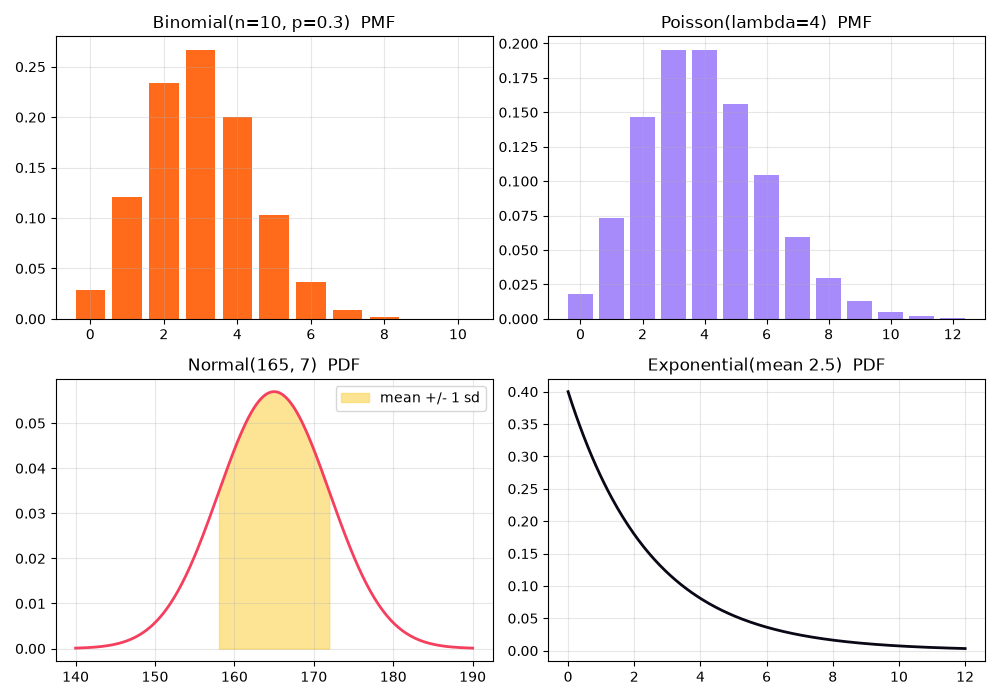

In [5]:
from IPython.display import Image, display
display(Image(filename='session-02_distributions.png'))  # chart saved by the cell above

## Example: `session-02_clt.py`

In [6]:
"""
Session 2 · Example 4: The Central Limit Theorem, seen with your own eyes
------------------------------------------------------------------------
Population: waiting times at a bank, which are strongly RIGHT-SKEWED
(exponential with mean 8 minutes). We draw thousands of samples of size
n = 2, 5, 30 and look at the distribution of the SAMPLE MEANS.

CLT: whatever the population shape, the sample mean is approximately
Normal(mu, sigma / sqrt(n)) when n is large enough (n >= 30 is a common rule).
Chart saved to: session-02_clt.png

Run:  python session-02_clt.py
"""
import numpy as np
from scipy import stats
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
mu = sigma = 8.0                    # for an exponential distribution, sd = mean
reps = 10_000

print(f"Population: exponential, mean {mu}, sd {sigma}, skewness 2.0")
print(f"{'n':>4} {'mean of means':>14} {'sd of means':>12} {'sigma/sqrt(n)':>14} {'skewness':>9}")
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
pop = rng.exponential(mu, size=reps)
axes[0].hist(pop, bins=60, color="#A78BFA", density=True)
axes[0].set_title("Population (skewed)")
for ax, n in zip(axes[1:], [2, 5, 30]):
    means = rng.exponential(mu, size=(reps, n)).mean(axis=1)
    print(f"{n:>4} {means.mean():>14.3f} {means.std(ddof=1):>12.3f} {sigma / np.sqrt(n):>14.3f} "
          f"{stats.skew(means):>9.3f}")
    ax.hist(means, bins=60, density=True, color="#FF6B1A", alpha=0.8)
    xs = np.linspace(means.min(), means.max(), 200)
    ax.plot(xs, stats.norm.pdf(xs, mu, sigma / np.sqrt(n)), color="#0A0716", lw=1.5, label="CLT normal")
    ax.set_title(f"Means of n = {n}"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("session-02_clt.png", dpi=100)

# Using the CLT: probability that the AVERAGE wait of 36 customers exceeds 10 minutes
se = sigma / np.sqrt(36)
z = (10 - mu) / se
print(f"\nP(mean wait of 36 customers > 10 min) ~ P(Z > {z:.2f}) = {stats.norm.sf(z):.4f}")
sim = rng.exponential(mu, size=(reps, 36)).mean(axis=1)
print(f"Simulation check: {np.mean(sim > 10):.4f}")
print("Saved chart: session-02_clt.png")

Population: exponential, mean 8.0, sd 8.0, skewness 2.0
   n  mean of means  sd of means  sigma/sqrt(n)  skewness
   2          8.052        5.770          5.657     1.477
   5          8.026        3.586          3.578     0.906
  30          7.982        1.466          1.461     0.336



P(mean wait of 36 customers > 10 min) ~ P(Z > 1.50) = 0.0668
Simulation check: 0.0723
Saved chart: session-02_clt.png


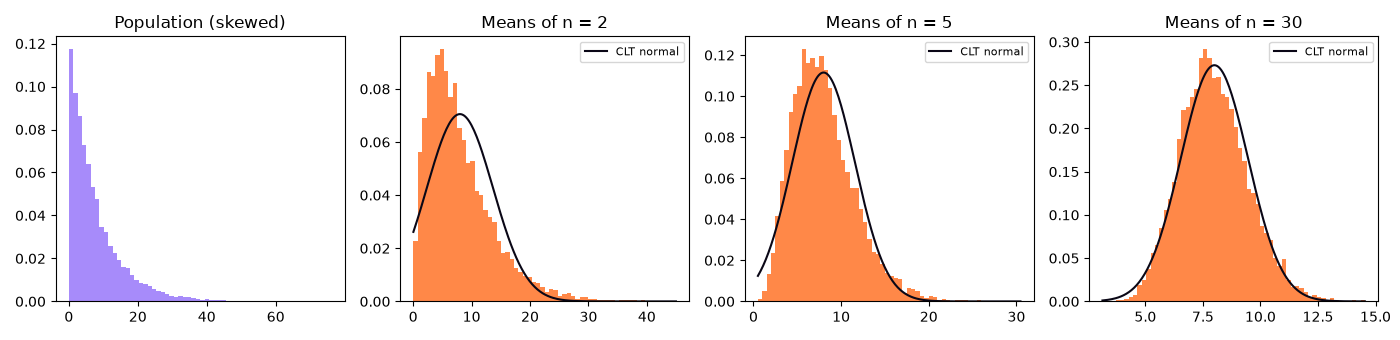

In [7]:
from IPython.display import Image, display
display(Image(filename='session-02_clt.png'))  # chart saved by the cell above

## Example: `session-02_problem_call_centre.py`

In [8]:
"""
Session 2 · Real-life problem: how many agents does the help-line need?
----------------------------------------------------------------------
PROBLEM
A bank's help-line receives on average 18 calls per hour between 9 and 10 am.
Each agent can handle 4 calls per hour. Management asks:
  1. What is the probability of more than 25 calls in that hour?
  2. How many agents are needed so that the chance of more calls than the team
     can handle is at most 5 %?
  3. A quality check finds 6 % of calls are complaints. Out of 18 calls,
     what is P(at least 3 complaints)? What is the expected number?
  4. Verify the answers with a Monte Carlo simulation of 100,000 mornings.

MODEL
Calls in an hour  ~ Poisson(lambda = 18)    (random, independent arrivals)
Complaints        ~ Binomial(n = 18, p = 0.06)

Run:  python session-02_problem_call_centre.py
"""
import math
import numpy as np
from scipy import stats

lam, per_agent = 18, 4
calls = stats.poisson(lam)

# 1. Tail probability
print(f"1. P(calls > 25) = {calls.sf(25):.4f}")

# 2. Smallest team whose capacity covers demand at least 95 % of the time
for agents in range(1, 15):
    capacity = agents * per_agent
    p_overload = calls.sf(capacity)          # P(calls > capacity)
    print(f"   {agents} agents -> capacity {capacity:>2} calls, P(overload) = {p_overload:.4f}")
    if p_overload <= 0.05:
        break
print(f"2. Hire {agents} agents (the 95th percentile of demand is {calls.ppf(0.95):.0f} calls).")

# 3. Complaints
comp = stats.binom(18, 0.06)
print(f"3. P(>= 3 complaints) = {comp.sf(2):.4f}, expected complaints = {comp.mean():.2f}")
# The same answer from the formula, to show there is no magic:
p_le2 = sum(math.comb(18, k) * 0.06 ** k * 0.94 ** (18 - k) for k in range(3))
print(f"   by formula: 1 - P(X <= 2) = {1 - p_le2:.4f}")

# 4. Monte Carlo check
rng = np.random.default_rng(2026)
mornings = rng.poisson(lam, size=100_000)
print(f"4. Simulated P(calls > 25)        = {np.mean(mornings > 25):.4f}")
print(f"   Simulated P(overload, {agents} agents) = {np.mean(mornings > agents * per_agent):.4f}")
complaints = rng.binomial(18, 0.06, size=100_000)
print(f"   Simulated P(>= 3 complaints)    = {np.mean(complaints >= 3):.4f}")

1. P(calls > 25) = 0.0446
   1 agents -> capacity  4 calls, P(overload) = 0.9999
   2 agents -> capacity  8 calls, P(overload) = 0.9929
   3 agents -> capacity 12 calls, P(overload) = 0.9083
   4 agents -> capacity 16 calls, P(overload) = 0.6249
   5 agents -> capacity 20 calls, P(overload) = 0.2693
   6 agents -> capacity 24 calls, P(overload) = 0.0683
   7 agents -> capacity 28 calls, P(overload) = 0.0103
2. Hire 7 agents (the 95th percentile of demand is 25 calls).
3. P(>= 3 complaints) = 0.0898, expected complaints = 1.08
   by formula: 1 - P(X <= 2) = 0.0898
4. Simulated P(calls > 25)        = 0.0446
   Simulated P(overload, 7 agents) = 0.0101
   Simulated P(>= 3 complaints)    = 0.0892


## Example: `session-02_project_monte_carlo.py`

In [9]:
"""
Session 2 · Mini project: Monte Carlo profit simulator for a food stall
----------------------------------------------------------------------
A student plans a weekend biryani stall at a university fest and must decide
how many plates to cook. Uncertainty everywhere:
  * visitors per day          ~ Poisson(mean 220)
  * each visitor buys a plate  with probability 0.35   (Binomial)
  * price 350 PKR, cost 180 PKR per cooked plate, unsold plates are wasted
Goal: simulate 20,000 days for several cooking quantities, report the expected
profit, the 5th-95th percentile range and P(loss), pick the best quantity, and
save a chart: session-02_project_monte_carlo.png

This is the 'newsvendor problem', a classic in operations research.
Run:  python session-02_project_monte_carlo.py
"""
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

PRICE, COST = 350, 180
DAYS = 20_000
rng = np.random.default_rng(11)

# Demand is simulated ONCE and reused for every option (common random numbers),
# so differences between options are not caused by luck.
visitors = rng.poisson(220, size=DAYS)
demand = rng.binomial(visitors, 0.35)
print(f"Demand per day: mean {demand.mean():.1f}, sd {demand.std(ddof=1):.1f}, "
      f"min {demand.min()}, max {demand.max()}")

def profit_for(cooked):
    sold = np.minimum(demand, cooked)
    return sold * PRICE - cooked * COST

options = range(50, 111, 5)
results = []
print(f"\n{'cooked':>6} {'E[profit]':>10} {'5th pct':>8} {'95th pct':>9} {'P(loss)':>8} {'P(sold out)':>11}")
for q in options:
    pr = profit_for(q)
    results.append((q, pr.mean()))
    print(f"{q:>6} {pr.mean():>10,.0f} {np.percentile(pr, 5):>8,.0f} {np.percentile(pr, 95):>9,.0f} "
          f"{np.mean(pr < 0):>8.3f} {np.mean(demand >= q):>11.3f}")

best_q, best_p = max(results, key=lambda t: t[1])
# Theory check: the optimal quantity is the demand quantile at (price - cost) / price
critical = (PRICE - COST) / PRICE
print(f"\nBest quantity by simulation: {best_q} plates (expected profit {best_p:,.0f} PKR)")
print(f"Newsvendor theory: cook the {critical:.3f} quantile of demand = {np.quantile(demand, critical):.0f} plates")

qs, ps = zip(*results)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(qs, ps, marker="o", color="#FF6B1A")
ax.axvline(best_q, color="#A78BFA", ls="--", label=f"best = {best_q}")
ax.set_xlabel("plates cooked"); ax.set_ylabel("expected profit (PKR)")
ax.set_title("Expected daily profit vs quantity cooked (20,000 simulated days)")
ax.grid(alpha=0.3); ax.legend()
fig.tight_layout(); fig.savefig("session-02_project_monte_carlo.png", dpi=100)
print("Saved chart: session-02_project_monte_carlo.png")

Demand per day: mean 77.1, sd 8.9, min 46, max 118

cooked  E[profit]  5th pct  95th pct  P(loss) P(sold out)
    50      8,500    8,500     8,500    0.000       1.000
    55      9,347    9,350     9,350    0.000       0.997
    60     10,176   10,200    10,200    0.000       0.979
    65     10,942   10,350    11,050    0.000       0.927
    70     11,546    9,450    11,900    0.000       0.804
    75     11,850    8,550    12,750    0.000       0.603
    80     11,771    7,650    13,600    0.000       0.382
    85     11,340    6,750    14,450    0.000       0.199
    90     10,656    5,850    15,300    0.000       0.083
    95      9,838    4,950    15,100    0.000       0.029
   100      8,964    4,050    14,200    0.001       0.008
   105      8,070    3,150    13,300    0.002       0.001
   110      7,171    2,250    12,400    0.008       0.000

Best quantity by simulation: 75 plates (expected profit 11,850 PKR)
Newsvendor theory: cook the 0.486 quantile of demand = 76 plates
Sa

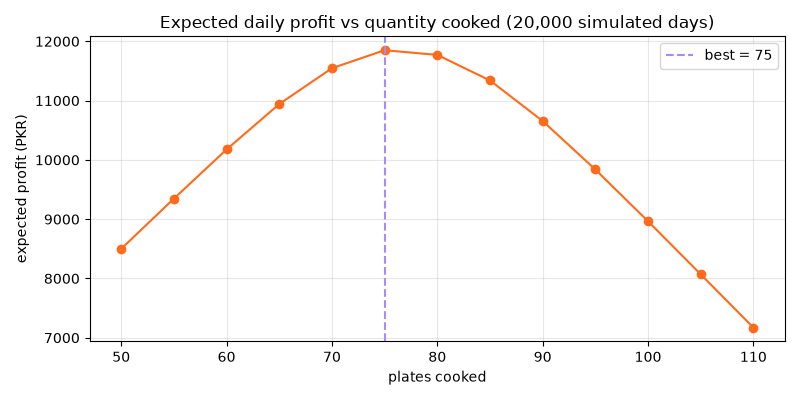

In [10]:
from IPython.display import Image, display
display(Image(filename='session-02_project_monte_carlo.png'))  # chart saved by the cell above